# Data Pipelines & Data Analytics Lifecycle
# Forecasting the Wind Power Production in Orkney

## Introduction

In this assignment you will play the role of a Data Scientist consultant for the Scottish and Southern Electricity Networks (SSEN). Among many other areas, the SSEN provides electricity for the Okrney islands, in Northern Scottland. This archipelago has significant wind and marine energy resources, and it generates over 100% of its 
net power from renewable sources, coming mainly from wind turbines situated across Orkney. This is good news for Orkney and the environment, but although wind farms provide emissions-free energy, they only generate electricity when the wind blows.

Your job? To design and implement a training pipeline, including data preprocessing, evaluation and model storing, for a small wind energy forecasting system. The goal here is to use weather forecasting data to predict the energy production for Orkney. You will need all your data scientist skills for insights, and you will have 
some libraries at your disposal, such as Scikit-Learn and MLFlow (and as many others as you might need). This Jupyter Notebook will help you started.

The steps you will complete in this project are:

- align the datasets
- create pipelines for preprocessing and prediction
- compare your pipelines with MLflow Tracking
- register your best model with MLflow Registry
- serve the best model
- package the project using MLProjects

Above this cell you will find an *Outline* button. Click it and an outline of this notebook should appear on the left bottom corner of the screen. This will help you navigate to a specific section.

**Dependencies**

If you've just created this workspace, install mlflow by typing the command below in the Terminal. If you already did this in a previous session, there is no need to install it again.

```
pip install mlflow
```

Now let's import all libraries necessary for this project.
The first time you will run a cell in this notebook, a dialogue box will appear asking if you want to Install/enable suggested extentions: python and jupyter. Go ahead and once that is finished select the created kernel.

In [73]:
import mlflow

# You will probably need these
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline

# This are for example purposes. You may discard them if you don't use them.
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from mlflow.models import infer_signature
from urllib.parse import urlparse


# Libraries for feature preprocessing (scaling and encoding), pipeline assembly, and modeling
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from sklearn.metrics import root_mean_squared_error, r2_score

<a name="data"></a> 

## Data exploration

You will work with three datasets:

**Power generation data** (`power.csv`)

* *Source:* Scottish and Southern Electricity Networks (SSEN)
* *Granularity:* 1-minute sampling
* *Target variable:* Total renewable power generation (MW)

Key fields:

* `time`: Timestamp of measurement
* `Total`: Renewable power generation (MW)

**Weather forecast data** (`weather.csv`)

* *Source:* UK Met Office
* *Granularity:* 3-hour intervals
* Forecasts include a *source time* (forecast creation) and a *target time* (forecasted timestamp)

Key fields:

* `time`: Target time of the forecast
* `Speed`: Wind speed (m/s)
* `Direction`: Wind direction (categorical string, e.g. "NW")
* `Source_time`: Forecast generation time
* `Lead_hours`: Forecast horizon

**Future forecasts** (`future.csv`)

* Weather forecasts to be used for generating future power predictions using your model

Let's first load the first 2 datasets.

In [74]:
power_df = pd.read_csv("data/power.csv", parse_dates=["time"], index_col="time")
wind_df = pd.read_csv("data/weather.csv", parse_dates=["time"], index_col="time")

Let's take a look at the resulting dataframes:

In [75]:
power_df

,ANM,Non-ANM,Total
time,,,
2021-12-11 13:39:00+00:00,10.195558,17.102,27.297558
2021-12-11 13:40:00+00:00,10.043559,17.582,27.625559
2021-12-11 13:41:00+00:00,10.961558,17.139,28.100558
2021-12-11 13:42:00+00:00,11.240559,16.194,27.434559
2021-12-11 13:43:00+00:00,10.672559,16.566,27.238559
...,...,...,...
2022-03-11 13:34:00+00:00,15.261000,18.144,33.405000
2022-03-11 13:35:00+00:00,15.751000,17.667,33.418000
2022-03-11 13:36:00+00:00,15.539998,17.766,33.305998


This table contains three columns, but closer inspection will reveal a clear relationship between those three. Can you spot that?

We are interested in the total power generation, regardless of the source type. Modify the table such that only the column of interest is kept.

In [76]:
### The Total column is the addition of ANM and Non-ANM. As we are only interested in predicting the total, we can get rid of these two columns
power_df = power_df.drop(columns=["ANM", "Non-ANM"])
power_df

,Total
time,
2021-12-11 13:39:00+00:00,27.297558
2021-12-11 13:40:00+00:00,27.625559
2021-12-11 13:41:00+00:00,28.100558
2021-12-11 13:42:00+00:00,27.434559
2021-12-11 13:43:00+00:00,27.238559
...,...
2022-03-11 13:34:00+00:00,33.405000
2022-03-11 13:35:00+00:00,33.418000
2022-03-11 13:36:00+00:00,33.305998


In [77]:
# Overview of wind data
wind_df

,Direction,Lead_hours,Source_time,Speed
time,,,,
2021-12-11 15:00:00+00:00,SSE,1,1639227600,11.17600
2021-12-11 18:00:00+00:00,SSW,1,1639238400,8.04672
2021-12-11 21:00:00+00:00,WSW,1,1639249200,11.17600
2021-12-12 00:00:00+00:00,WSW,1,1639260000,8.94080
2021-12-12 03:00:00+00:00,SW,1,1639270800,9.83488
...,...,...,...,...
2022-03-10 21:00:00+00:00,S,1,1646938800,9.83488
2022-03-11 00:00:00+00:00,SSE,1,1646949600,11.17600
2022-03-11 03:00:00+00:00,SSE,1,1646960400,9.83488


This table contains four columns, but lead hours and source time are irrelevant here. Answer: Source_time is the date when the prediction was made. and Lead_hours is the number of hours
between the prediction was made and the actually predicted time. Because we are only interested in predicting the total renewable generation, these two features do not add any
predictive value. It also contains a column named Direction, which shows the cardinal direction that the wind is blowing from. For example, the record containing ’SW’ in the wind direction field would indicate that the wind is blowing from the South-West (and to
the North-East). Since our models can only handle numeric data, you will need to perform some transformation on this feature later on.

Look at the table's index. Do both data sources contain the same intervals? And if not, what problems could arise when merging the data? Answer: The indices represent different time intervals: the wind dataset registers data every 3 hours, while the power dataframe registers data every minute. If we use an inner merge, we use the indices as our merge key. However, we would lose a lot of observations from the power dataframe. Even when the timestamps match in both dataframes, the power record will not represent the total or average power generated over those 3 hours, but rather just the instantaneous generation of that single minute. Aligning a 3-hour forecast with an isolated 1-minute snapshot introduces a lot of noise, which will lead to poor model predictions.

### Data alignment
We have two dataframes, one with weather forecasts and one with power generation. To do some analysis on the relationship between these two datasets, it might be useful to align the datasets.

**Example**

In [78]:
# Joining the data
draft_join = power_df.join(wind_df, how="inner")
draft_join

,Total,Direction,Lead_hours,Source_time,Speed
time,,,,,
2021-12-11 15:00:00+00:00,27.864560,SSE,1,1639227600,11.17600
2021-12-11 18:00:00+00:00,26.091558,SSW,1,1639238400,8.04672
2021-12-11 21:00:00+00:00,16.727561,WSW,1,1639249200,11.17600
2021-12-12 00:00:00+00:00,21.364559,WSW,1,1639260000,8.94080
2021-12-12 03:00:00+00:00,21.231557,SW,1,1639270800,9.83488
...,...,...,...,...,...
2022-03-10 21:00:00+00:00,30.431001,S,1,1646938800,9.83488
2022-03-11 00:00:00+00:00,29.714001,SSE,1,1646949600,11.17600
2022-03-11 03:00:00+00:00,25.842002,SSE,1,1646960400,9.83488


Joining the two datasets with an inner join means keeping only those records that match their index. Although this will work, you may notice that most of our data is discarded due to the unmatching time intervals. You may want to explore other possible ways to merge the data; you can argue for using a specific method or experiment with both later on. For now, try out a different way to align the datasets.

In [79]:
### TODO -> JOIN THE TWO DATASETS ###
# Answer: To join both data frames I will resample the index from the power data frame. So It will represent the data to represent the average total genereated power for a 3 hours time
# period

power_3h = power_df[["Total"]].resample("3h").mean()
# now that the data frame is resampled, I will use the same inner join approach as the indices are almost the same
joined_dfs = power_3h.join(wind_df, how="inner")

# beacuse Lead_hours and Source_time are irrelevant, we can discard them
joined_dfs = joined_dfs.drop(columns=["Lead_hours", "Source_time"])
joined_dfs

,Total,Direction,Speed
time,,,
2021-12-11 15:00:00+00:00,27.621048,SSE,11.17600
2021-12-11 18:00:00+00:00,21.135542,SSW,8.04672
2021-12-11 21:00:00+00:00,20.616209,WSW,11.17600
2021-12-12 00:00:00+00:00,21.223876,WSW,8.94080
2021-12-12 03:00:00+00:00,19.418303,SW,9.83488
...,...,...,...
2022-03-10 21:00:00+00:00,30.011595,S,9.83488
2022-03-11 00:00:00+00:00,27.386623,SSE,11.17600
2022-03-11 03:00:00+00:00,26.954428,SSE,9.83488


In [80]:
joined_dfs.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 716 entries, 2021-12-11 15:00:00+00:00 to 2022-03-11 12:00:00+00:00
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Total      676 non-null    float64
 1   Direction  716 non-null    object 
 2   Speed      716 non-null    float64
dtypes: float64(2), object(1)
memory usage: 22.4+ KB


As we can see in the joined_dfs, even when we aggregate the power_df data to match the granularity from wind_df, there are some null values. This is due to the fact that
power_df does not have all the data for all the time period. But rather, there are some gaps as shown in the dataframe below. 

In [81]:
# Analysing data gaps in the power_df

power_df = power_df.sort_index()
time_diff = power_df.index.to_series().diff()

gaps = pd.DataFrame(
    {
        "gap_start": power_df.index[:-1],
        "gap_end": power_df.index[1:],
        "gap_duration": time_diff[1:],
    }
)

large_gaps = gaps[gaps["gap_duration"] > pd.Timedelta(minutes=5)]
large_gaps.sort_values(by=["gap_duration"], ascending=False)

,gap_start,gap_end,gap_duration
time,,,
2021-12-26 12:05:00+00:00,2021-12-25 02:15:00+00:00,2021-12-26 12:05:00+00:00,1 days 09:50:00
2022-03-02 10:47:00+00:00,2022-03-01 22:02:00+00:00,2022-03-02 10:47:00+00:00,0 days 12:45:00
2021-12-27 14:39:00+00:00,2021-12-27 02:09:00+00:00,2021-12-27 14:39:00+00:00,0 days 12:30:00
2021-12-28 13:23:00+00:00,2021-12-28 02:09:00+00:00,2021-12-28 13:23:00+00:00,0 days 11:14:00
2021-12-30 11:06:00+00:00,2021-12-30 01:28:00+00:00,2021-12-30 11:06:00+00:00,0 days 09:38:00
...,...,...,...
2022-01-07 06:15:00+00:00,2022-01-07 06:09:00+00:00,2022-01-07 06:15:00+00:00,0 days 00:06:00
2022-01-07 04:58:00+00:00,2022-01-07 04:52:00+00:00,2022-01-07 04:58:00+00:00,0 days 00:06:00
2022-01-07 04:50:00+00:00,2022-01-07 04:44:00+00:00,2022-01-07 04:50:00+00:00,0 days 00:06:00


To handle the periods where total power generation is missing, we use interpolation with the time method. This draws a straight line between the last known value before the gap and the value right after it to estimate the missing numbers based on time.

We only make this approximation if the gap is small. A maximum of two 3-hour periods (6 hours). If the gap is larger, the method leaves the values as null so we can drop them. We use this limit because over a short time gap, power generation is usually close to what it was right before and right after. For bigger gaps, the approximation loses accuracy and we risk creating fake numbers that do not represent the real power generated.

In [82]:
power_3h = power_df[["Total"]].resample("3h").mean()
power_3h["Total"] = power_3h["Total"].interpolate(method="time", limit=2)
power_3h = power_3h.dropna(subset=["Total"])

# once we have dealed with the time gaps, we can merge the wind and power data frames
joined_dfs_3h = power_3h.join(wind_df, how="inner")

# beacuse Lead_hours and Source_time are irrelevant, we can discard them
joined_dfs_3h = joined_dfs_3h.drop(columns=["Lead_hours", "Source_time"])
joined_dfs_3h

,Total,Direction,Speed
time,,,
2021-12-11 15:00:00+00:00,27.621048,SSE,11.17600
2021-12-11 18:00:00+00:00,21.135542,SSW,8.04672
2021-12-11 21:00:00+00:00,20.616209,WSW,11.17600
2021-12-12 00:00:00+00:00,21.223876,WSW,8.94080
2021-12-12 03:00:00+00:00,19.418303,SW,9.83488
...,...,...,...
2022-03-10 21:00:00+00:00,30.011595,S,9.83488
2022-03-11 00:00:00+00:00,27.386623,SSE,11.17600
2022-03-11 03:00:00+00:00,26.954428,SSE,9.83488


In [83]:
joined_dfs_3h.info()  # now there are zero null values

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 704 entries, 2021-12-11 15:00:00+00:00 to 2022-03-11 12:00:00+00:00
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Total      704 non-null    float64
 1   Direction  704 non-null    object 
 2   Speed      704 non-null    float64
dtypes: float64(2), object(1)
memory usage: 22.0+ KB


### Understanding the data: EDA

It can be also useful to plot our datasets to see what relationships they might hold.

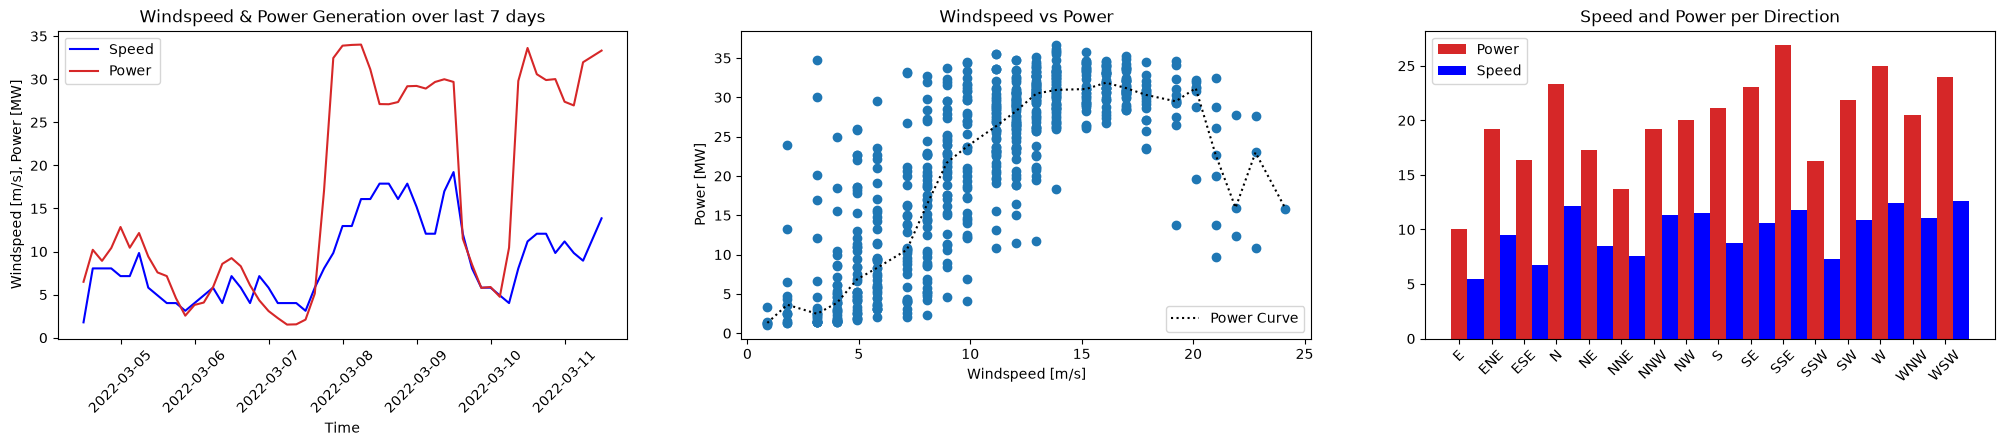

In [84]:
# Subplots
fig, ax = plt.subplots(1, 3, figsize=(25, 4))

# Speed and Power for the last 7 days
ax[0].plot(
    joined_dfs_3h["Speed"].tail(int(7 * 24 / 3)), label="Speed", color="blue"
)  # Since the datasets are joined every three hours, we need the last 7 days times 24 hours diveded by 3 hours
ax[0].plot(
    joined_dfs_3h["Total"].tail(int(7 * 24 / 3)), label="Power", color="tab:red"
)  # Since the datasets are joined every three hours, we need the last 7 days times 24 hours diveded by 3 hours
ax[0].set_title("Windspeed & Power Generation over last 7 days")
ax[0].set_xlabel("Time")
ax[0].tick_params(axis="x", labelrotation=45)
ax[0].set_ylabel("Windspeed [m/s], Power [MW]")
ax[0].legend()

# Speed vs Total (Power Curve nature)
ax[1].scatter(joined_dfs_3h["Speed"], joined_dfs_3h["Total"])
power_curve = joined_dfs_3h.groupby("Speed").median(numeric_only=True)["Total"]
ax[1].plot(power_curve.index, power_curve.values, "k:", label="Power Curve")
ax[1].legend()
ax[1].set_title("Windspeed vs Power")
ax[1].set_ylabel("Power [MW]")
ax[1].set_xlabel("Windspeed [m/s]")

# Speed and Power per Wind Direction
wind_grouped_by_direction = (
    joined_dfs_3h.groupby("Direction").mean(numeric_only=True).reset_index()
)
bar_width = 0.5
x = np.arange(len(wind_grouped_by_direction.index))

ax[2].bar(x, wind_grouped_by_direction.Total, width=0.5, label="Power", color="tab:red")
ax[2].bar(
    x + bar_width,
    wind_grouped_by_direction.Speed,
    width=0.5,
    label="Speed",
    color="blue",
)
ax[2].legend()
ax[2].set_xticks(x)
ax[2].set_xticklabels(wind_grouped_by_direction.Direction)
ax[2].tick_params(axis="x", labelrotation=45)
ax[2].set_title("Speed and Power per Direction");

These plots should already give us an intuition of the different relationships between features. There is a clear relationship between the wind speed and the power generation from the turbines. But that relationship is not completely linear. Which plot shows that? Finally, it seems like the power generation also depends of where the wind is coming from. Maybe this could also be a useful feature.

After analyzing these charts, the main takeaway is that wind speed and power do not follow a linear relationship. In graphs A and B, we can see that as wind speed increases, power also increases. However, this increase has a limit of around 35 MW, where turbines stop generating more power due to safety reasons. Most importantly, the direction of the wind matters significantly, with winds coming from the south and west generating the highest amounts of electricity

In order to plot the relationship between wind speed and power generation we have performed a very simple join with the two datasets. But since the intervals are not the same, a lot of data is discarded (can you spot where in the code this happens?). 

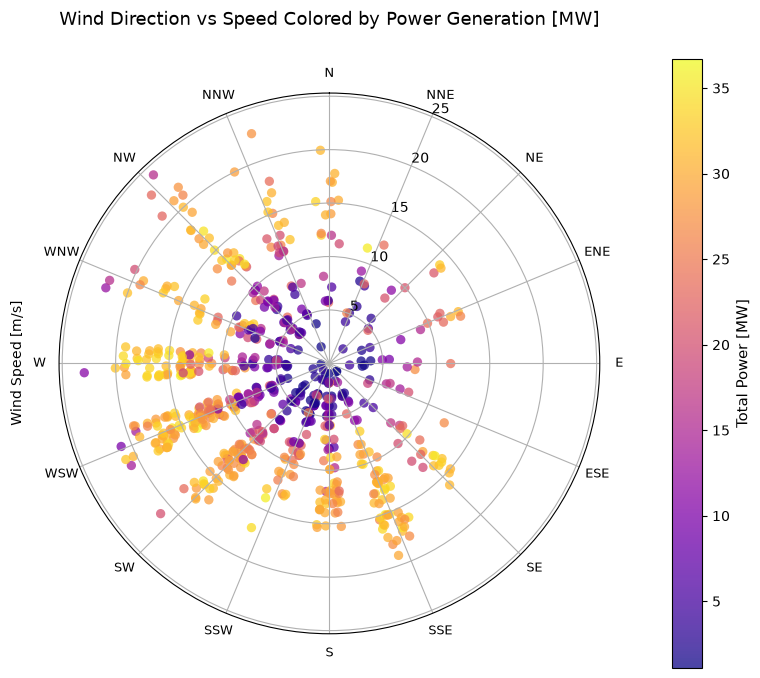

In [85]:
### TODO -> DO SOME EXTRA EDA ON THE DATA ###
# Answer: To double check that the wind direction has a relevant role I have implemented a wind rose scatter plot. From this graph we can clearly see that most of the wind
# comes from the west and south, especially between W, WSW, SW, SSW, and S. When the wind blows from these directions and the speed goes above 10 to 12 m/s, we get the highest
# power generation. On the other hand, wind from the east is very rare and doesn't generate much power.

# 1. Map 16 cardinal compass directions to meteorological degrees
cardinal_to_degrees = {
    "N": 0.0,
    "NNE": 22.5,
    "NE": 45.0,
    "ENE": 67.5,
    "E": 90.0,
    "ESE": 112.5,
    "SE": 135.0,
    "SSE": 157.5,
    "S": 180.0,
    "SSW": 202.5,
    "SW": 225.0,
    "WSW": 247.5,
    "W": 270.0,
    "WNW": 292.5,
    "NW": 315.0,
    "NNW": 337.5,
}

# 2. Convert Direction to radians for polar plotting
plot_df = joined_dfs_3h.copy()
plot_df["degrees"] = plot_df["Direction"].map(cardinal_to_degrees)
plot_df["radians"] = np.deg2rad(plot_df["degrees"])
np.random.seed(42)
plot_df["radians_jitter"] = plot_df["radians"] + np.deg2rad(
    np.random.uniform(-5, 5, size=len(plot_df))
)
plot_df["speed_jitter"] = plot_df["Speed"] + np.random.uniform(
    -0.2, 0.2, size=len(plot_df)
)

# 3. Create polar scatter plot
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})

# Set meteorological orientation (0° = North at top, clockwise angles)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)

scatter = ax.scatter(
    plot_df["radians_jitter"],
    plot_df["speed_jitter"],
    c=plot_df["Total"],
    cmap="plasma",
    alpha=0.75,
    edgecolors="none",
    s=45,
)

# Set 16 cardinal labels around the perimeter
compass_angles = np.deg2rad(list(cardinal_to_degrees.values()))
compass_labels = list(cardinal_to_degrees.keys())
ax.set_xticks(compass_angles)
ax.set_xticklabels(compass_labels, fontsize=9)

ax.set_title(
    "Wind Direction vs Speed Colored by Power Generation [MW]\n", fontsize=13, pad=15
)
ax.set_ylabel("Wind Speed [m/s]", labelpad=25)
cbar = fig.colorbar(scatter, ax=ax, orientation="vertical", shrink=0.8, pad=0.1)
cbar.set_label("Total Power [MW]", fontsize=11)

plt.tight_layout()
plt.show()

## Pipeline and data transformations

Now that we have our data, we need to construct the pipeline to process this data and pass it to our Machine Learning model. For this, use the Pipeline class from Scikit-Learn.

This class applies a list of transformations to your data, and pass the final state to an estimator (your model). Intermediate steps of the pipeline must be ‘transforms’, that is, they must implement fit and transform methods. The final estimator only needs to implement fit.

You can find more information about Scikit-Learn's Pipeline [here](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).

**Example**

In [86]:
# A very basic pipeline
pipeline_example = Pipeline(
    [
        # Transformations
        ("Scaler", StandardScaler()),
        # Estimator
        ("Linear Regression", LinearRegression()),
    ]
)

In [87]:
### TODO -> CREATE YOUR OWN PIPELINE ###
# Answer: All preprocessing lives inside the pipeline, so exactly the same steps run at training, evaluation, serving and on future.csv.
# - Missing values: SimpleImputer in every branch (median for Speed, most frequent compass point for Direction).
# - Direction: a compass label is mapped to an angle in radians and then to (sin, cos). This keeps the circular nature of
#   direction (359 degrees and 1 degree end up next to each other), which one-hot encoding or a plain number would not.
# - Speed: scaled with StandardScaler for the regularised linear model (Ridge); tree models do not need scaling.

# The 16 compass points in clockwise order, so that index * 22.5 degrees is the meteorological angle
COMPASS = [
    "N",
    "NNE",
    "NE",
    "ENE",
    "E",
    "ESE",
    "SE",
    "SSE",
    "S",
    "SSW",
    "SW",
    "WSW",
    "W",
    "WNW",
    "NW",
    "NNW",
]


def index_to_sin_cos(idx):
    """Map a compass index (0..15) to a point on the unit circle: (sin, cos) of its angle in radians."""
    angle = idx * 2 * np.pi / len(COMPASS)
    return np.hstack([np.sin(angle), np.cos(angle)])


# Direction: label -> index (unknown or missing -> NaN) -> impute -> radians -> (sin, cos)
direction_pipe = Pipeline(
    [
        (
            "ordinal",
            OrdinalEncoder(
                categories=[COMPASS],
                handle_unknown="use_encoded_value",
                unknown_value=np.nan,
            ),
        ),
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("sincos", FunctionTransformer(index_to_sin_cos)),
    ]
)

# Preprocessor for the linear model: speed is imputed and then scaled
linear_processor = ColumnTransformer(
    [
        ("dir", direction_pipe, ["Direction"]),
        (
            "speed",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            ["Speed"],
        ),
    ]
)

# Preprocessor for tree models: speed is imputed but not scaled
tree_processor = ColumnTransformer(
    [
        ("dir", direction_pipe, ["Direction"]),
        ("speed", SimpleImputer(strategy="median"), ["Speed"]),
    ]
)

pipeline = Pipeline([("processor", linear_processor), ("regressor", Ridge())])

**Design of the preprocessing pipeline**

**Missing values.** Missing values are handled inside the pipeline with `SimpleImputer`, not only during the earlier data alignment. The alignment step already interpolates short gaps in the power data and drops the rest, so the training data has no NaNs. The imputers are still needed because the pipeline is also used on new data (the `future.csv` forecasts or requests sent to the served model), where a speed value may be missing or a direction label may be unknown. Being part of the pipeline, the imputation values (the median speed and the most frequent compass point) are learned from the training data only and re-used unchanged afterwards.

**Wind direction: cyclical encoding.** Direction is an angle, so it is circular: 359° and 1° are only 2° apart, but as plain numbers they look very far apart. One-hot encoding avoids a false ordering but treats N and NNE as just as unrelated as N and S, and it needs 16 columns. Instead, each compass label is converted to an angle in radians (index × 2π/16) and then to a point on the unit circle, `(sin θ, cos θ)`. Neighbouring directions get neighbouring values, 359° and 1° are almost the same point, and the information is compressed into two features. Both are needed: `sin` alone gives the same value for two different directions (for example NE and NW), while the pair `(sin, cos)` identifies each direction uniquely.

**Scaling.** Features have different units and ranges: wind speed is measured in m/s (roughly 0–25), while the sin/cos features are between -1 and 1. `StandardScaler` rescales a feature to zero mean and unit variance: `z = (x - mean) / std`. This matters for models that are sensitive to the size of the features, such as Ridge. Its L2 penalty shrinks all coefficients in the same way, so a feature with a small numeric range, which needs a large coefficient to have an effect, would be penalised more purely because of its units. After scaling, coefficients are comparable and the penalty treats all features fairly. Scaling also helps gradient-based solvers converge faster. The mean and standard deviation are computed on the training data only and then applied to the test data; computing them on all data would leak information about the test set. Because the scaler sits inside the `Pipeline`, this also holds within each cross-validation fold. Tree-based models (Random Forest, XGBoost) split on thresholds, so only the order of the values matters and scaling has no effect on them; the sin/cos features are already bounded, so they are not scaled either. For this reason only the Ridge pipeline scales `Speed`.

### Evaluate your model

Now that you have a preprocessing pipeline ready, along with the final estimator, you may want to know how well your model performs. Choose the method you prefer, with special attention to the selected metric.

**Example**

In [88]:
# Select our feature variables and our target variable.
joined_dfs = power_df.join(wind_df).dropna()

X_example = joined_dfs["Speed"].values.reshape(-1, 1)
y_example = joined_dfs["Total"].values.reshape(-1, 1)

# Split the data so we can test how well our model performs in unseen data
X_train_example, X_test_example, y_train_example, y_test_example = train_test_split(
    X_example, y_example
)  # -> You might want to use another split method

# Train our model
pipeline_example.fit(X_train_example, y_train_example)

# Evaluate the model, using MAE as a metric
mae_example = mean_absolute_error(
    pipeline_example.predict(X_test_example), y_test_example
)
print(mae_example)

2026/11/01 14:12:19 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'f2f60528219743268525ed98ba464411', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/11/01 14:12:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run awesome-deer-232 at: http://127.0.0.1:5000/#/experiments/2/runs/f2f60528219743268525ed98ba464411
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
5.6021018662967395


My approach: Instead of using a standard train_test_split, I kept the data sorted chronologically. A regular split shuffles the observations, but because we are working with time-series data, we want to prevent data leakage and avoid using future data to predict the past. Therefore, I used the first 80% of the observations as the training set and reserved the remaining 20% for testing.  Additionally, I chose a regularized regression (Ridge) instead of a simple linear regression. Wind speed is scaled, so all features are on a comparable scale and the penalty term shrinks the coefficients of speed and of the direction components fairly. The penalty also keeps the coefficients stable and limits overfitting, and since direction is encoded as sin/cos (two correlated, bounded features) it helps to stabilize the fit.

In [89]:
joined_dfs_3h = joined_dfs_3h.sort_index()

# features
X = joined_dfs_3h[["Direction", "Speed"]]
y = joined_dfs_3h["Total"]

# chronological train/test split
index_split = int(len(joined_dfs_3h) * 0.8)

X_train = X.iloc[:index_split]
y_train = y.iloc[:index_split]
X_test = X.iloc[index_split:]
y_test = y.iloc[index_split:]


# making predictions
pipeline.fit(X_train, y_train)
my_predictions = pipeline.predict(X_test)
mae = mean_absolute_error(my_predictions, y_test)
print(mae)

2026/11/01 14:12:24 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'b8ca1bdba96c44588fcc643dfbc0d4e9', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


2026/11/01 14:12:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run welcoming-fish-170 at: http://127.0.0.1:5000/#/experiments/2/runs/b8ca1bdba96c44588fcc643dfbc0d4e9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
5.240757520153692


Let's see how our predictions look compared to the true values.

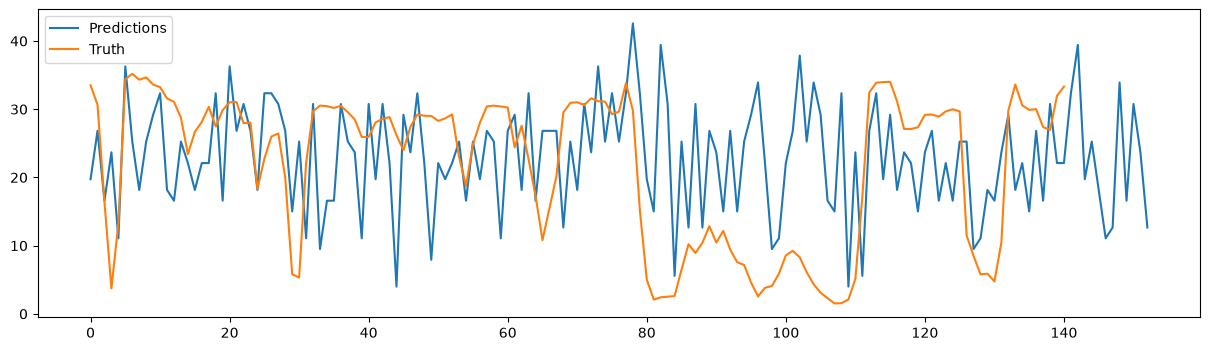

In [90]:
predictions = pipeline_example.predict(X_test_example)

plt.figure(figsize=(15, 4))
plt.plot(np.arange(len(predictions)), predictions, label="Predictions")
plt.plot(np.arange(len(y_test)), y_test, label="Truth")
plt.legend()
plt.show()

HINT: Pay special attention to this type of data: We are dealing with Time series data (i.e. data that is recorded over consistent intervals of time). It might be a good idea not to randomly split the data, since it wouldn't respect the temporal order and may cause data-leakage, unintentionally inferring the trend of future samples.

In [91]:
# Use your preferred method to evaluate your model
### TODO -> SPLIT THE DATA INTO TRAIN AND TEST SETS, AND EVALUATE YOUR MODEL ###
# Answer:
tscv = TimeSeriesSplit(
    n_splits=5
)  # object that will split our data into 5 time-ordered folds
cv_mae_scores = []  # MAE of each fold

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    X_tr, X_val = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[test_idx]

    pipeline.fit(X_tr, y_tr)
    preds = pipeline.predict(X_val)
    fold_mae = mean_absolute_error(y_val, preds)
    cv_mae_scores.append(fold_mae)

print(f"Mean CV MAE: {np.mean(cv_mae_scores):.2f} MW (+/- {np.std(cv_mae_scores):.2f})")

2026/11/01 14:12:29 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'a5e12b832a134ea5b964853931f78618', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/11/01 14:12:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:12:34 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '5dcccc5676fa4ed99280ba72e0bb7ad2', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


🏃 View run funny-shrike-385 at: http://127.0.0.1:5000/#/experiments/2/runs/a5e12b832a134ea5b964853931f78618
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/11/01 14:12:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:12:38 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'beb02758c6944d3093c2adadd4b8360d', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


🏃 View run big-colt-384 at: http://127.0.0.1:5000/#/experiments/2/runs/5dcccc5676fa4ed99280ba72e0bb7ad2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/11/01 14:12:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:12:43 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'f2a675b5a9f94a2080ab0c092fbd3b70', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


🏃 View run bold-goat-430 at: http://127.0.0.1:5000/#/experiments/2/runs/beb02758c6944d3093c2adadd4b8360d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/11/01 14:12:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:12:48 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '5138d02808b349d2aaa8e84348711b86', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow


🏃 View run suave-deer-222 at: http://127.0.0.1:5000/#/experiments/2/runs/f2a675b5a9f94a2080ab0c092fbd3b70
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/11/01 14:12:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run upbeat-chimp-399 at: http://127.0.0.1:5000/#/experiments/2/runs/5138d02808b349d2aaa8e84348711b86
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Mean CV MAE: 5.80 MW (+/- 0.86)


After evaluating the results, the single test MAE is 5.24 MW. This is a good result. However, it only measures the model's performance during that specific time split. So, if that period had steady, moderate winds, the model would produce artificially optimistic results.

To challenge this, I also used rolling walk-forward validation. In this approach, we split our data into 5 time-ordered folds and calculate the average MAE across them. The result shows that the model is off by an average of 5.80 MW from actual generation. Another positive takeaway is that the spread (a standard deviation of 0.86 MW) remains narrow across the folds, confirming the model remains stable and does not collapse when wind patterns shift.

## Tracking your experiments with MLFlow
We have a working model with a certain accuracy. But wouldn't it be better to try different parameters and different models before deciding for one?

This is exactly what we will do using the MLFlow library. MLflow is an open source platform to manage the ML lifecycle, including experimentation, reproducibility, deployment, and a central model registry. This will allow us for easy comparison of all our model experiments.

Example
When using MLFlow locally to log our experiments, we need to start a "local server". We can do this easily by running the following in our command line interface (in the Terminal):

```
mlflow server --host 127.0.0.1 --port 5000
```

Once you start the server you will see the following information in the Terminal: `Uvicorn running on http://127.0.0.1:5000`.

The server is located at our localhost `127.0.0.1, port 5000`. We will use this information to indicate where our experiment logs will be shown.

In [92]:
# Start an MLflow run
mlflow.sklearn.autolog()  # This is to help us track scikit learn metrics.
mlflow.set_tracking_uri(
    "http://127.0.0.1:5000"
)  # We set the MLFlow UI to display in our local host.

# Set the experiment and run name
experiment_name = "LinearRegression-Example"  # Think how to best organise experiments - for example by model type
run_name = "Simple_regression"  # Give explicit names

mlflow.set_experiment(experiment_name)

with mlflow.start_run(run_name=run_name) as run:
    # Train our model
    pipeline_example.fit(X_train_example, y_train_example)

    # Evaluate the model, using MAE as a metric
    predictions = pipeline_example.predict(X_test_example)
    mae = mean_absolute_error(predictions, y_test_example)

    mlflow.log_metric("MAE", mae)

2026/11/01 14:12:52 WARNING mlflow.utils.autologging_utils: MLflow sklearn autologging is known to be compatible with 1.6.0 <= scikit-learn, but the installed version is 1.5.2. If you encounter errors during autologging, try upgrading / downgrading scikit-learn to a compatible version, or try upgrading MLflow.
2026/11/01 14:12:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run Simple_regression at: http://127.0.0.1:5000/#/experiments/1/runs/71a75e5610cc487abdf7e395675c44e1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In the example above you can see that:
- we are using `sklearn.autolog()` to automatically log `scikit-learn` specific metrics
- we set an experiment_name; if the experiment doesn't exist it will create a new one, otherwise it will use the already existent experiment
- we set a run_name; same as above
- after model training we record the MAE to compare between runs

Click on either of the links above to see your experiments. Have a look at the Overview, Model metrics, and Artifacts.

Now have a look at the *Explorer* tab on the left and notice the newly created files and folders: 
- `mlflow.db` - a database containing metadata regarding experiments, runs, and parameters that you logged
- `mlartifacts/` folders
    - each folder will correspond to a run
    - the `models` folder contains data about the logged models, such as the envinroment file, a .pkl file containing the model, and a MLmodel complete description of the model; have a look at each of those

Now try out different set-ups. You can experiment with different pre-processing steps, models, and parameters. If you need a tutorial on MLflow Tracking you can find one [here](https://mlflow.org/docs/latest/ml/tracking/).

**Evaluation metrics**

Every model is scored with the same three regression metrics, so the runs can be compared fairly in the MLflow UI. They are computed in two ways: as the mean and standard deviation over the 5 time-series cross-validation folds (`Mean_CV_*`, `Std_CV_*`), and once on the held-out test split, the last 20% of the data in time (`Test_*`).

- **MAE** (mean absolute error): the average size of the error in MW. Easy to interpret and not dominated by a few large misses.
- **RMSE** (root mean squared error): also in MW, but squaring the errors before averaging punishes large misses more. A big gap between RMSE and MAE means the model makes occasional large errors, which matters for grid planning.
- **R²** (coefficient of determination): the share of the variation in power generation that the model explains. 1 is a perfect fit, 0 means the model is no better than always predicting the average, and it is negative if it is worse. It is unitless, so it also shows how good an error of a given size is.

In [ ]:
### TODO -> SET YOUR OWN EXPERIMENT SETUP ###
# Here, you may want to stop and think what is the best way to iterate(!) through all the models and experiments you want to try.
# Instead of running your code everytime you want to change something, you could try to list all your desired experiments and run them all sequentially in one go (gridsearch style).
# Answer: My approach consist on using XGBoost and Random forest regressor, with the Ridge pipeline from before as a linear baseline. I decided to test these two models because they are really good at capturing non-linear relationships.
# As we saw during the EDA, the data contains a S shape distribution: zero power below cut-in wind speed, cubic power increase in the middle, and a flat ceiling at rated capacity.
# They also automatically capture how wind speed and direction work together without needing extra math tricks, making them far better suited to handle real-world weather swings and pull down our prediction error.

# the models that I want to try are XGBoost regressor and random forest regressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

experiment_name = "fernando_ml"
mlflow.set_experiment(experiment_name)

# the preprocessors (tree_processor and linear_processor) are defined together with the pipeline above:
# the tree models get unscaled speed, Ridge gets scaled speed. Ridge is kept as a linear baseline.
models = [
    ("Ridge", Ridge(), linear_processor),
    ("RandomForest", RandomForestRegressor(random_state=42), tree_processor),
    ("XGBoost", XGBRegressor(random_state=42), tree_processor),
]


def evaluate(y_true, y_pred):
    """The same three regression metrics for every model."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


for model_name, regressor, processor in models:
    pipeline = Pipeline([("prep", processor), ("reg", regressor)])

    with mlflow.start_run(run_name=model_name):
        # 5 fold temporal evaluation (each fold trains on the past and validates on the next block)
        cv_scores = {"MAE": [], "RMSE": [], "R2": []}
        for train_idx, val_idx in tscv.split(X):
            X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

            pipeline.fit(X_tr, y_tr)
            for metric, value in evaluate(y_val, pipeline.predict(X_val)).items():
                cv_scores[metric].append(value)

        for metric, values in cv_scores.items():
            mlflow.log_metric(f"Mean_CV_{metric}", float(np.mean(values)))
            mlflow.log_metric(f"Std_CV_{metric}", float(np.std(values)))

        # Final model: fit on the whole training split and evaluate once on the held-out (later) test split.
        # This is the last fit in the run, so it is the model that MLflow stores.
        pipeline.fit(X_train, y_train)
        test_scores = evaluate(y_test, pipeline.predict(X_test))
        for metric, value in test_scores.items():
            mlflow.log_metric(f"Test_{metric}", float(value))

        print(
            f"{model_name:<13} CV   MAE {np.mean(cv_scores['MAE']):.2f} (+/- {np.std(cv_scores['MAE']):.2f}) | "
            f"RMSE {np.mean(cv_scores['RMSE']):.2f} | R2 {np.mean(cv_scores['R2']):.3f}"
        )
        print(
            f"{'':<13} Test MAE {test_scores['MAE']:.2f} | RMSE {test_scores['RMSE']:.2f} | R2 {test_scores['R2']:.3f}"
        )

2026/11/01 14:12:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:13:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:13:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

Ridge         CV   MAE 5.80 (+/- 0.86) | RMSE 7.38 | R2 0.373
              Test MAE 5.24 | RMSE 6.27 | R2 0.665
🏃 View run Ridge at: http://127.0.0.1:5000/#/experiments/2/runs/1a3abd9dfa8845bdad6f4ba66b290ec6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/11/01 14:13:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:13:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:13:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

RandomForest  CV   MAE 4.51 (+/- 0.89) | RMSE 6.30 | R2 0.580
              Test MAE 4.35 | RMSE 6.19 | R2 0.674
🏃 View run RandomForest at: http://127.0.0.1:5000/#/experiments/2/runs/9b0ddd7ea3c34ec19606530486414b5a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


2026/11/01 14:13:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:14:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/01 14:14:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mec

XGBoost       CV   MAE 4.80 (+/- 0.93) | RMSE 6.70 | R2 0.528
              Test MAE 4.61 | RMSE 6.62 | R2 0.627
🏃 View run XGBoost at: http://127.0.0.1:5000/#/experiments/2/runs/29c3d4f1f2b04ab681fadb7fe14684f9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


**Choosing the best model**

The three models are compared on the same metrics (MAE, RMSE, R²). The best model is selected with the **mean cross-validated MAE**, because the cross-validation folds are the validation data used to choose between models. The test split is kept as an independent check of the chosen model and is not used to pick it. MAE is the main criterion because it is in MW, is easy to interpret for grid planning, and is not dominated by a few large errors.

The model with the lowest mean CV MAE is registered in the MLflow Model Registry under its own name, and that registered version is the one loaded for the future predictions and served below.

In [ ]:
from mlflow import MlflowClient

client = MlflowClient()
exp = client.get_experiment_by_name("fernando_ml")

# Keep the most recent run of each model (the experiments cell can be run several times)
runs = client.search_runs([exp.experiment_id], order_by=["start_time DESC"])
latest_run = {}
for r in runs:
    if "Mean_CV_MAE" in r.data.metrics:
        latest_run.setdefault(r.data.tags["mlflow.runName"], r)

# Select the best model by cross-validated MAE (validation folds), not by the test split
print(f"{'model':<13} {'CV MAE':>7} {'Test MAE':>9} {'Test RMSE':>10} {'Test R2':>8}")
for name, r in latest_run.items():
    m = r.data.metrics
    print(
        f"{name:<13} {m['Mean_CV_MAE']:>7.2f} {m['Test_MAE']:>9.2f} {m['Test_RMSE']:>10.2f} {m['Test_R2']:>8.3f}"
    )

model_name = min(
    latest_run, key=lambda name: latest_run[name].data.metrics["Mean_CV_MAE"]
)
best_run = latest_run[model_name]

# Register the best model in the MLflow Model Registry under its own name
mv = mlflow.register_model(f"runs:/{best_run.info.run_id}/model", model_name)
model_version = mv.version
print(
    f"\nBest model: {model_name} (lowest mean CV MAE) -> registered as '{model_name}', version {model_version}"
)

model          CV MAE  Test MAE  Test RMSE  Test R2
XGBoost          4.80      4.61       6.62    0.627
RandomForest     4.51      4.35       6.19    0.674
Ridge            5.80      5.24       6.27    0.665


Successfully registered model 'RandomForest'.
2026/11/01 14:14:26 WARNING mlflow.tracking._model_registry.fluent: Run with id 9b0ddd7ea3c34ec19606530486414b5a has no artifacts at artifact path 'model', registering model based on models:/m-ef6bea52632048649628995654dc6459 instead
2026/11/01 14:14:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: RandomForest, version 1



Best model: RandomForest (lowest mean CV MAE) -> registered as 'RandomForest', version 1


Created version '1' of model 'RandomForest'.


### Comparing models

Suppose you have ran some experiments, trying different pre-processing steps, models, and parameters. To easily compare the results from our experiments, we can use the MLFlow interface.

**Example.**
We have been logging our experiments in our local server. We can access the UI by opening the localhost address in any browser. You should see a list of all the experiments under *Experiments*. When logging multiple runs with different parameters/metrics, you will be able to easily compare them using the "Chart View". Make sure to try this out.

## Registering the best model

Now suppose you have tried many different models with different parameters, you might want to register the best one. To do this, we can use again the UI. You can follow the instructions below or this [visual guide](register_model_guide.pdf) which you can open in the repository:

- In the Experiments list, select the name of the experiment you want. 
- Click Models in the left panel.
- Click on the model you want to use, in this case it's named "model"
- Then "Register Model".
- First "Select a model", click "Create New Model" and name it "LinearRegression"

Now, if you go to the Homepage, on the "Models" tab, you will see that you registered the model.

In case of doubt, you can check the [documentation](https://mlflow.org/docs/latest/ml/model-registry/tutorial/).

**Using a registered model**

Now that we have registered our best model, we can use it for future predictions. We can retrieve the weather forecasts for the next days, and make predictions of power generation.

**Example.**
First we need the new forecast data:

In [95]:
future_df = pd.read_csv("data/future.csv")
future_df["time"] = pd.to_datetime(future_df["time"], utc=True)
future_df["Source_time"] = pd.to_datetime(future_df["Source_time"], unit="s", utc=True)
future_df.head(10)

,time,Direction,Lead_hours,Source_time,Speed
0,2022-03-11 15:00:00+00:00,SE,3,2022-03-11 11:00:00+00:00,15.19936
1,2022-03-11 18:00:00+00:00,SE,6,2022-03-11 11:00:00+00:00,16.09344
2,2022-03-11 21:00:00+00:00,SE,9,2022-03-11 11:00:00+00:00,16.98752
3,2022-03-12 00:00:00+00:00,SSE,12,2022-03-11 11:00:00+00:00,16.09344
4,2022-03-12 03:00:00+00:00,SSE,15,2022-03-11 11:00:00+00:00,12.96416
5,2022-03-12 06:00:00+00:00,SSE,18,2022-03-11 11:00:00+00:00,8.04672
6,2022-03-12 09:00:00+00:00,SSE,21,2022-03-11 11:00:00+00:00,8.94080
7,2022-03-12 12:00:00+00:00,SE,24,2022-03-11 11:00:00+00:00,11.17600
8,2022-03-12 15:00:00+00:00,SSE,27,2022-03-11 11:00:00+00:00,12.07008
9,2022-03-12 18:00:00+00:00,SSW,30,2022-03-11 11:00:00+00:00,8.94080


Then, we can retrieve any saved model and use it to predict on the new data:

In [ ]:
# model_name and model_version come from the registration cell above (the best model)

model_uri = f"models:/{model_name}/{model_version}"
model = mlflow.pyfunc.load_model(model_uri=model_uri)

X_forecast = future_df[["Speed", "Direction"]]
predictions = model.predict(X_forecast)

predictions_df = future_df[["time", "Direction", "Speed"]].copy()
predictions_df["Predicted_Power"] = predictions

print(
    f"Model: {model_name} (version {model_version}) - first 10 predictions on future.csv"
)
print(predictions_df.head(10).to_string(index=False))

Model: RandomForest (version 1) - first 10 predictions on future.csv
                     time Direction    Speed  Predicted_Power
2022-03-11 15:00:00+00:00        SE 15.19936        31.798313
2022-03-11 18:00:00+00:00        SE 16.09344        32.160751
2022-03-11 21:00:00+00:00        SE 16.98752        31.008130
2022-03-12 00:00:00+00:00       SSE 16.09344        32.236916
2022-03-12 03:00:00+00:00       SSE 12.96416        31.118864
2022-03-12 06:00:00+00:00       SSE  8.04672        23.452153
2022-03-12 09:00:00+00:00       SSE  8.94080        25.014184
2022-03-12 12:00:00+00:00        SE 11.17600        24.405344
2022-03-12 15:00:00+00:00       SSE 12.07008        30.639004
2022-03-12 18:00:00+00:00       SSW  8.94080        23.651866


## Serving your model

So far, we have trained several models and registered the best one. Often times, we will want to deploy the best model in such a way that other people can take advantage of it, by sending a request with data and getting back predictions. In this project you will only serve the model locally, a step usually done before deployment to ensure that the model works as expected. 

Serving a model refers to the process of making a trained machine learning model available to receive input data and provide predictions or inferences based on that data. In other words, when you serve a model, you set it up in a way that it can be queried with new data, and it will produce predictions or outputs based on the patterns it learned during training.

Serving a model is a critical step in the machine learning lifecycle, as it allows you to leverage the model's predictive capabilities in real-world applications. When a model is served, it becomes accessible to applications, websites, or other systems that need to utilize its predictions.

You have tried serving the model in [one of the previous exercises](https://github.com/LSDA-BDM/exercise-mlflow-caiso). Run the same command to serve your current model.

> Note. The current configuration is slightly different that in the exercise. You won't have to call `mlflow run .` as in the exercise. Do you know why? Answer: We do not need to run this command because we already trained, tracked, and registered the model in MLflow. However, before serving the model, you will have to set the tracking URI in the terminal with:
> ```bash
> export MLFLOW_TRACKING_URI=http://localhost:5000
> ```

Serve the model and then use `curl` to test that it worked.

## Packaging your project

Lastly, we want to make sure that others are able to run the project and do further development. As opposed to just making the model available as before (with serving) now you will package the project in order to make it reproducible.

Reproducibility refers to the ability of researchers, developers, and practitioners to recreate the exact same results, analyses, and outcomes from a given set of source code and data. In that sense, MLflow Projects is a standardized way to encapsulate an experiment in a reproducible
manner, so colleagues or other stakeholders can reproduce your code. This is done by specifying all the dependencies using a 'pip' environment file, a 'conda' environment file, or a docker environment. Here we will take the ‘pip‘ approach.

An MLflow project consists (at least) of:

- The code you want to package, including the data for your experiments (if needed). Jupyter Notebooks are not supported, so you will have to more the relevant code in `.py` file; you can check the `script.py` file provided for an example.
- A requirements.txt file specifying the dependencies for the code (in this case a text file with ‘pip‘-installable dependencies).
- An MLproject file specifying which environment file to use, parameters accepted, and the entry points to the code.

First, try to run the script `script.py` with

```bash
python script.py
```
> Note: For this to run you must have started an mlflow server as shown in Tracking your experiments.

Then, create a similar script containing your experiments; also create the other files necessary for an MLProject. Have a look at [this exercise](https://github.com/LSDA-BDM/exercise-polynomial/) that explains how MLflow projects work.

## Notes and hints

Here are a few resources you can use to inform your design decisions for your experiments:

**Joining the data.** How do you join and align the data will affect the amount of data you end up with for training your model. Make sure you explain your decision and reflect upon its pros and cons. Some resources for pandas: [Join](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html), [Merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html), [Resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html).

**Wind direction encoding.** You will most likely need to transform the wind direction into a numerical feature. Some possibilities to consider, make sure you reflect on their advantages and disadvantages:
- [OneHotEncoding](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- Transforming to degrees or radians with a [custom transformer](https://towardsdatascience.com/pipelines-custom-transformers-in-scikit-learn-ef792bbb3260/)
- Converting speed and direction to a [2-dimensional vector](https://www.tensorflow.org/tutorials/structured_data/time_series#wind)

**Scaling.** Think what is the range of your features. Is your model affected by this? Should you scale your features? You should explain why would you do it, or why it's not necessary. Check [Scikit-Learn's Preprocessing and Normalization](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling) or this [article](https://www.geeksforgeeks.org/ml-feature-scaling-part-2/).

**Feature transformations.** If you want to apply different transformations to different columns (e.g. categorical and numerical), you can use the [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html).

**Missing values.** Check [Scikit-Learn’s imputers](https://scikit-learn.org/stable/modules/impute.html) to see different options for dealing with missing values. 

**Splitting and shuffling.** You are working with time series data. Is it acceptable to do a random shuffle on the data when splitting for training? If so, why? If not, how can you split the data? Make sure to argue your decision. Check [Scikit-Learn’s TimeSeries Split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html#sklearn.model_selection.TimeSeriesSplit) or this [article](https://machinelearningmastery.com/backtest-machine-learning-models-time-series-forecasting/).